In [ ]:
!pip install mlxtend -q
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from mlxtend.frequent_patterns import apriori
from mlxtend.frequent_patterns import association_rules

import warnings
warnings.filterwarnings("ignore")

plt.style.use("ggplot")


In [ ]:
#Assignment 1
#Business Objective

'''Identify combinations of books frequently purchased together and improve:
Cross selling
Shelf placement
Combo offers
Customer footfall'''

#Constraints
'''Limited inventory
Competition from online stores
Customer preference changes'''

In [ ]:
df=pd.read_csv('/content/book.csv')

df.head()

,ChildBks,YouthBks,CookBks,DoItYBks,RefBks,ArtBks,GeogBks,ItalCook,ItalAtlas,ItalArt,Florence
0,0,1,0,1,0,0,1,0,0,0,0
1,1,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0
3,1,1,1,0,1,0,1,0,0,0,0
4,0,0,1,0,0,0,1,0,0,0,0


In [ ]:
print(df.shape)

df.info()

df.describe()

(2000, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   ChildBks   2000 non-null   int64
 1   YouthBks   2000 non-null   int64
 2   CookBks    2000 non-null   int64
 3   DoItYBks   2000 non-null   int64
 4   RefBks     2000 non-null   int64
 5   ArtBks     2000 non-null   int64
 6   GeogBks    2000 non-null   int64
 7   ItalCook   2000 non-null   int64
 8   ItalAtlas  2000 non-null   int64
 9   ItalArt    2000 non-null   int64
 10  Florence   2000 non-null   int64
dtypes: int64(11)
memory usage: 172.0 KB


,ChildBks,YouthBks,CookBks,DoItYBks,RefBks,ArtBks,GeogBks,ItalCook,ItalAtlas,ItalArt,Florence
count,2000.000000,2000.000000,2000.00000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,0.423000,0.247500,0.43100,0.282000,0.214500,0.241000,0.276000,0.113500,0.037000,0.048500,0.108500
std,0.494159,0.431668,0.49534,0.450086,0.410578,0.427797,0.447129,0.317282,0.188809,0.214874,0.311089
min,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,0.000000,1.00000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [ ]:
data_dict=pd.DataFrame({
"Column":df.columns,
"Datatype":df.dtypes.values
})

data_dict

,Column,Datatype
0,ChildBks,int64
1,YouthBks,int64
2,CookBks,int64
3,DoItYBks,int64
4,RefBks,int64
5,ArtBks,int64
6,GeogBks,int64
7,ItalCook,int64
8,ItalAtlas,int64
9,ItalArt,int64


In [ ]:
#1moment bussiness decision
df.mean()

#2 MBD
df.var()

#3MBD
df.skew()

#4 MBD
df.kurt()

,0
ChildBks,-1.904591
YouthBks,-0.629266
CookBks,-1.924154
DoItYBks,-1.060795
RefBks,-0.062077
ArtBks,-0.531428
GeogBks,-0.995084
ItalCook,3.951475
ItalAtlas,22.123718
ItalArt,15.711779


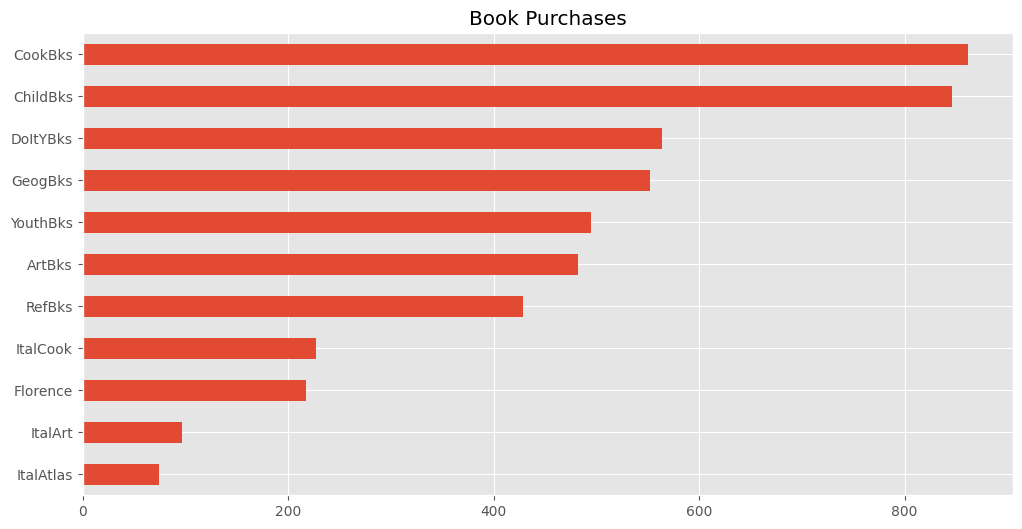

In [ ]:
#EDA
plt.figure(figsize=(12,6))

df.sum().sort_values().plot(
kind='barh'
)

plt.title("Book Purchases")
plt.show()

In [ ]:
#preprocessing
df=df.astype(bool)

In [ ]:
#Apriori
freq=apriori(
df,
min_support=0.10,
use_colnames=True
)

freq.head()

,support,itemsets
0,0.4230,(ChildBks)
1,0.2475,(YouthBks)
2,0.4310,(CookBks)
3,0.2820,(DoItYBks)
4,0.2145,(RefBks)


In [ ]:
#rule generation
rules=association_rules(
freq,
metric='lift',
min_threshold=1
)

rules.sort_values(
'confidence',
ascending=False
)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
29,(ItalCook),(CookBks),0.1135,0.4310,0.1135,1.000000,2.320186,1.0,0.064582,inf,0.641850,0.263341,1.000000,0.631671
83,"(ArtBks, DoItYBks)",(CookBks),0.1235,0.4310,0.1015,0.821862,1.906873,1.0,0.048272,3.194159,0.542591,0.224062,0.686929,0.528681
90,"(DoItYBks, GeogBks)",(CookBks),0.1325,0.4310,0.1085,0.818868,1.899926,1.0,0.051392,3.141354,0.546010,0.238462,0.681666,0.535304
96,"(ArtBks, GeogBks)",(CookBks),0.1275,0.4310,0.1035,0.811765,1.883445,1.0,0.048547,3.022812,0.537602,0.227473,0.669182,0.525952
54,"(ChildBks, RefBks)",(CookBks),0.1515,0.4310,0.1225,0.808581,1.876058,1.0,0.057204,2.972534,0.550345,0.266304,0.663587,0.546402
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,(CookBks),"(DoItYBks, GeogBks)",0.4310,0.1325,0.1085,0.251740,1.899926,1.0,0.051392,1.159357,0.832449,0.238462,0.137453,0.535304
75,(ChildBks),"(DoItYBks, GeogBks)",0.4230,0.1325,0.1045,0.247045,1.864490,1.0,0.048452,1.152127,0.803571,0.231707,0.132040,0.517862
81,(ChildBks),"(ArtBks, GeogBks)",0.4230,0.1275,0.1020,0.241135,1.891253,1.0,0.048067,1.149743,0.816724,0.227425,0.130240,0.520567
97,(CookBks),"(ArtBks, GeogBks)",0.4310,0.1275,0.1035,0.240139,1.883445,1.0,0.048547,1.148237,0.824355,0.227473,0.129099,0.525952


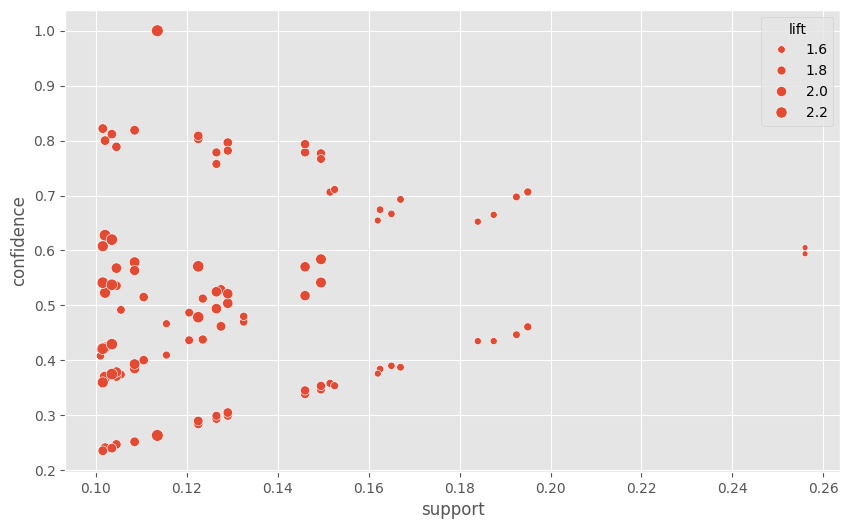

In [ ]:
#visualization
plt.figure(figsize=(10,6))

sns.scatterplot(
data=rules,
x='support',
y='confidence',
size='lift'
)

plt.show()

In [ ]:
#interpretation
rules[['antecedents',
'consequents',
'support',
'confidence',
'lift']]

,antecedents,consequents,support,confidence,lift
0,(YouthBks),(ChildBks),0.1650,0.666667,1.576044
1,(ChildBks),(YouthBks),0.1650,0.390071,1.576044
2,(CookBks),(ChildBks),0.2560,0.593968,1.404179
3,(ChildBks),(CookBks),0.2560,0.605201,1.404179
4,(DoItYBks),(ChildBks),0.1840,0.652482,1.542511
...,...,...,...,...,...
95,"(CookBks, GeogBks)",(ArtBks),0.1035,0.537662,2.230964
96,"(ArtBks, GeogBks)",(CookBks),0.1035,0.811765,1.883445
97,(CookBks),"(ArtBks, GeogBks)",0.1035,0.240139,1.883445
98,(ArtBks),"(CookBks, GeogBks)",0.1035,0.429461,2.230964


In [ ]:
#BUSINESS DECISION
'''Create combo bundles
Shelf optimization
Loyalty offers
Personalized recommendation'''

In [ ]:
import pandas as pd
from mlxtend.preprocessing import TransactionEncoder

#ASSIGNMENT 2

# Read the groceries data line by line
transactions = []
with open('/content/groceries.csv', 'r') as file:
    for line in file:
        transactions.append(line.strip().split(','))

# Convert the list of transactions into a one-hot encoded DataFrame
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df = pd.DataFrame(te_ary, columns=te.columns_)

df.head()

,Instant food products,UHT-milk,abrasive cleaner,artif. sweetener,baby cosmetics,baby food,bags,baking powder,bathroom cleaner,beef,...,turkey,vinegar,waffles,whipped/sour cream,whisky,white bread,white wine,whole milk,yogurt,zwieback
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False


In [ ]:
#converting transaction
transactions=[]

for i in range(len(df)):

    transactions.append(
        [
            str(x)
            for x in df.iloc[i]
            if str(x)!="nan"
        ]
    )

In [ ]:
#One Hot Encoder
from mlxtend.preprocessing import TransactionEncoder

te=TransactionEncoder()

arr=te.fit(
transactions
).transform(
transactions
)

groceries=pd.DataFrame(
arr,
columns=te.columns_
)

groceries.head()

,False,True
0,True,True
1,True,True
2,True,True
3,True,True
4,True,True


In [ ]:
#Apriori implementation
freq=apriori(
groceries,
min_support=0.02,
use_colnames=True
)

rules=association_rules(
freq,
metric='lift',
min_threshold=1
)

rules.sort_values(
'lift',
ascending=False
)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,(True),(False),1.0,1.0,1.0,1.0,1.0,1.0,0.0,inf,0.0,1.0,0.0,1.0
1,(False),(True),1.0,1.0,1.0,1.0,1.0,1.0,0.0,inf,0.0,1.0,0.0,1.0


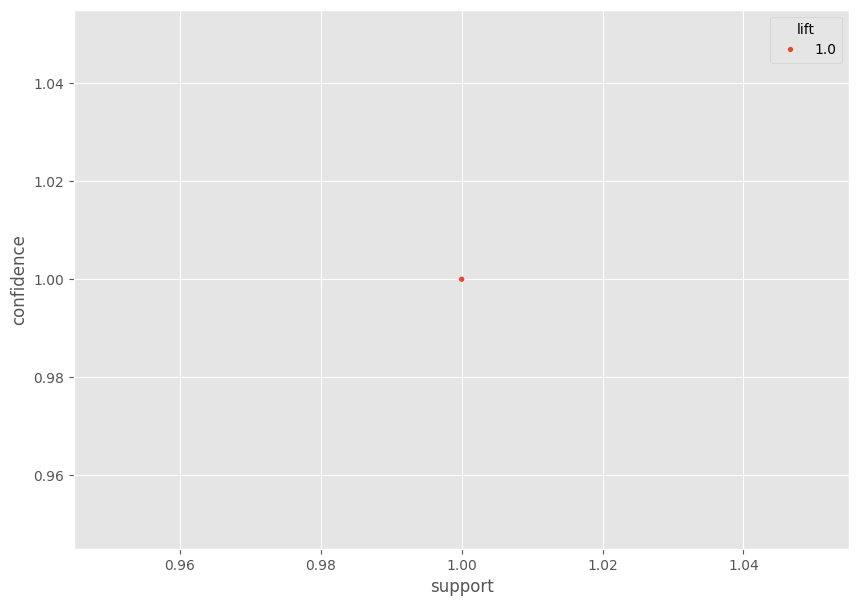

In [ ]:
#visualization
plt.figure(figsize=(10,7))

sns.scatterplot(
x='support',
y='confidence',
size='lift',
data=rules
)

plt.show()

In [ ]:
#Business Decision
'''Store layout optimization
Product bundling
Combo discounts'''

In [ ]:
#ASSIGNMENT 3
movies=pd.read_csv('/content/my_movies.csv')

movies.head()

,Sixth Sense,Gladiator,LOTR1,Harry Potter1,Patriot,LOTR2,Harry Potter2,LOTR,Braveheart,Green Mile
0,1,0,1,1,0,1,0,0,0,1
1,0,1,0,0,1,0,0,0,1,0
2,0,0,1,0,0,1,0,0,0,0
3,1,1,0,0,1,0,0,0,0,0
4,1,1,0,0,1,0,0,0,0,0


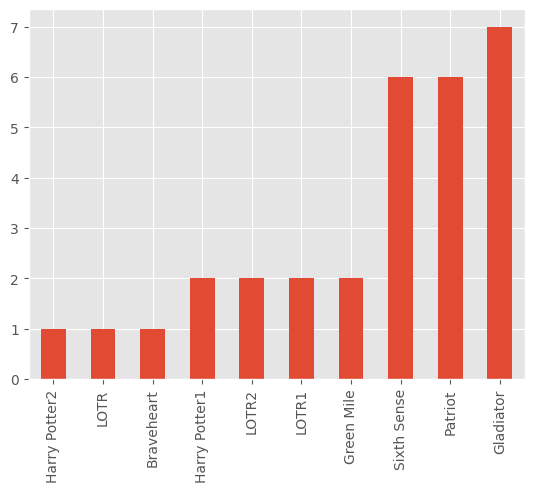

In [ ]:
#EDA
movies.sum().sort_values().plot(
kind='bar'
)

plt.show()

In [ ]:
#Apriori
freq=apriori(
movies.astype(bool),
min_support=0.2,
use_colnames=True
)

rules=association_rules(
freq,
metric='lift',
min_threshold=1
)

rules

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,(Sixth Sense),(Gladiator),0.6,0.7,0.5,0.833333,1.190476,1.0,0.08,1.8,0.400000,0.625000,0.444444,0.773810
1,(Gladiator),(Sixth Sense),0.7,0.6,0.5,0.714286,1.190476,1.0,0.08,1.4,0.533333,0.625000,0.285714,0.773810
2,(Sixth Sense),(Patriot),0.6,0.6,0.4,0.666667,1.111111,1.0,0.04,1.2,0.250000,0.500000,0.166667,0.666667
3,(Patriot),(Sixth Sense),0.6,0.6,0.4,0.666667,1.111111,1.0,0.04,1.2,0.250000,0.500000,0.166667,0.666667
4,(Sixth Sense),(Green Mile),0.6,0.2,0.2,0.333333,1.666667,1.0,0.08,1.2,1.000000,0.333333,0.166667,0.666667
5,(Green Mile),(Sixth Sense),0.2,0.6,0.2,1.000000,1.666667,1.0,0.08,inf,0.500000,0.333333,1.000000,0.666667
6,(Gladiator),(Patriot),0.7,0.6,0.6,0.857143,1.428571,1.0,0.18,2.8,1.000000,0.857143,0.642857,0.928571
7,(Patriot),(Gladiator),0.6,0.7,0.6,1.000000,1.428571,1.0,0.18,inf,0.750000,0.857143,1.000000,0.928571
8,(LOTR1),(LOTR2),0.2,0.2,0.2,1.000000,5.000000,1.0,0.16,inf,1.000000,1.000000,1.000000,1.000000
9,(LOTR2),(LOTR1),0.2,0.2,0.2,1.000000,5.000000,1.0,0.16,inf,1.000000,1.000000,1.000000,1.000000


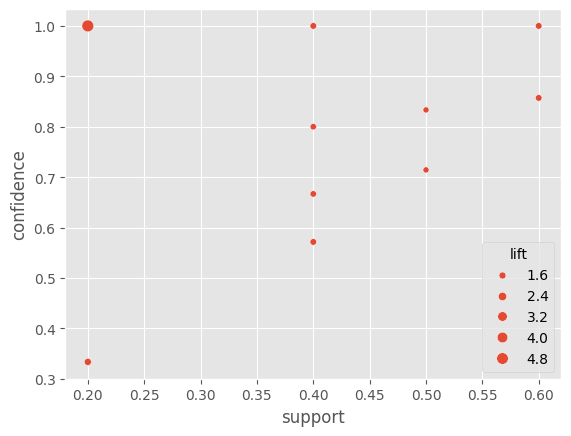

In [ ]:
#visualization
sns.scatterplot(
data=rules,
x='support',
y='confidence',
size='lift'
)

plt.show()

In [ ]:
#interpretation
'''Users watching LOTR1 likely watch LOTR2.'''

In [ ]:
#ASSIGNMENT 4
phone=pd.read_csv('/content/myphonedata.csv')
phone.head()

,red,white,green,yellow,orange,blue
0,1,1,1,0,0,0
1,0,1,0,0,1,0
2,0,1,0,0,0,1
3,1,1,0,0,1,0
4,1,0,0,0,0,1


In [ ]:
#building model
freq=apriori(
phone.astype(bool),
min_support=0.2,
use_colnames=True
)

rules=association_rules(
freq,
metric='confidence',
min_threshold=0.5
)

rules

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,(white),(red),0.636364,0.545455,0.363636,0.571429,1.047619,1.0,0.016529,1.060606,0.125,0.444444,0.057143,0.619048
1,(red),(white),0.545455,0.636364,0.363636,0.666667,1.047619,1.0,0.016529,1.090909,0.100,0.444444,0.083333,0.619048
2,(blue),(red),0.545455,0.545455,0.363636,0.666667,1.222222,1.0,0.066116,1.363636,0.400,0.500000,0.266667,0.666667
3,(red),(blue),0.545455,0.545455,0.363636,0.666667,1.222222,1.0,0.066116,1.363636,0.400,0.500000,0.266667,0.666667
4,(white),(blue),0.636364,0.545455,0.363636,0.571429,1.047619,1.0,0.016529,1.060606,0.125,0.444444,0.057143,0.619048
5,(blue),(white),0.545455,0.636364,0.363636,0.666667,1.047619,1.0,0.016529,1.090909,0.100,0.444444,0.083333,0.619048


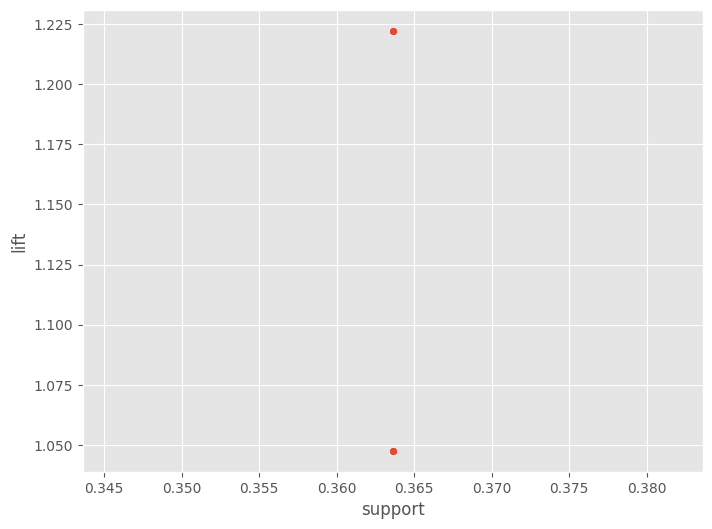

In [ ]:
#visualization
plt.figure(
figsize=(8,6)
)

sns.scatterplot(
data=rules,
x='support',
y='lift'
)

plt.show()

In [ ]:
#Business Decision
'''Regional launch strategy
Product bundles
Color preference analysis'''

In [ ]:
#Assignment5
retail=pd.read_csv('/content/transactions_retail1.csv',header=None)
retail.head()

,0,1,2,3,4,5
0,'HANGING','HEART','HOLDER','T-LIGHT','WHITE',NaN
1,'LANTERN','METAL','WHITE',NaN,NaN,NaN
2,'COAT','CREAM','CUPID','HANGER','HEARTS',NaN
3,'BOTTLE','FLAG','HOT','KNITTED','UNION','WATER'
4,'HEART.','HOTTIE','RED','WHITE','WOOLLY',NaN


In [ ]:
#converting transactions
transactions=[]

for i in range(len(retail)):

    transactions.append(
        retail.iloc[i]
        .dropna()
        .astype(str)
        .tolist()
    )

In [ ]:
#encoding
from mlxtend.preprocessing import TransactionEncoder

te=TransactionEncoder()

encoded=te.fit(
transactions
).transform(
transactions
)

retail_df=pd.DataFrame(
encoded,
columns=te.columns_
)

In [ ]:
#building apriori
freq=apriori(
retail_df,
min_support=0.01,
use_colnames=True
)

rules=association_rules(
freq,
metric='lift',
min_threshold=1
)

rules.head()

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,('3'),('OF'),0.033011,0.090179,0.012868,0.389806,4.322580,1.0,0.009891,1.491036,0.794897,0.116639,0.329325,0.266249
1,('OF'),('3'),0.090179,0.033011,0.012868,0.142692,4.322580,1.0,0.009891,1.127937,0.844844,0.116639,0.113426,0.266249
2,('SET'),('3'),0.091069,0.033011,0.016222,0.178125,5.395944,1.0,0.013215,1.176565,0.896301,0.150398,0.150068,0.334766
3,('3'),('SET'),0.033011,0.091069,0.016222,0.491406,5.395944,1.0,0.013215,1.787143,0.842487,0.150398,0.440448,0.334766
4,('4'),('OF'),0.016073,0.090179,0.011680,0.726669,8.058072,1.0,0.010230,3.328642,0.890209,0.123500,0.699577,0.428093


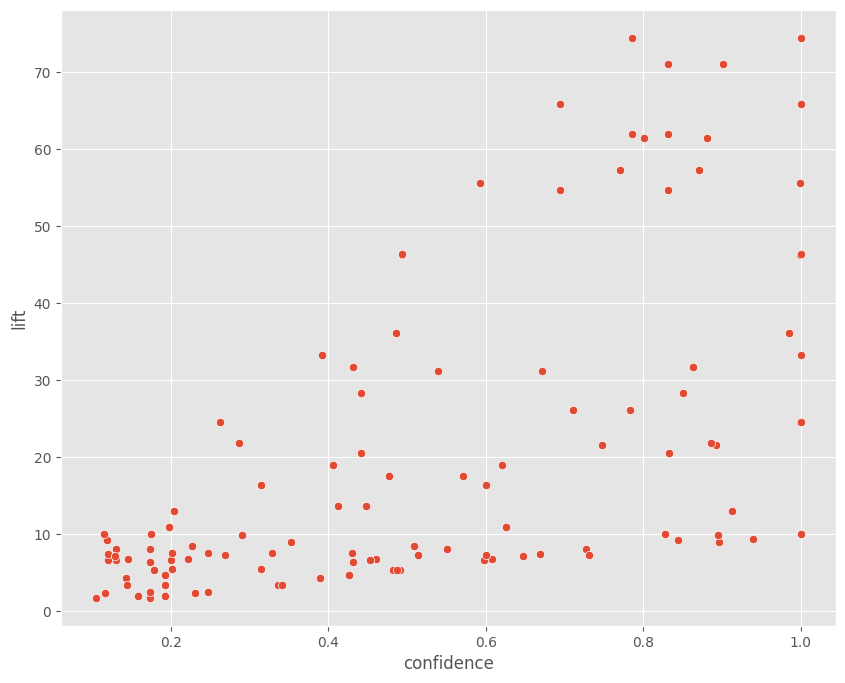

In [ ]:
#visualization
plt.figure(
figsize=(10,8)
)

sns.scatterplot(
data=rules,
x='confidence',
y='lift'
)

plt.show()

In [ ]:
#matrix evalustion
rules[[
'support',
'confidence',
'lift',
'leverage',
'conviction'
]]

,support,confidence,lift,leverage,conviction
0,0.012868,0.389806,4.322580,0.009891,1.491036
1,0.012868,0.142692,4.322580,0.009891,1.127937
2,0.016222,0.178125,5.395944,0.013215,1.176565
3,0.016222,0.491406,5.395944,0.013215,1.787143
4,0.011680,0.726669,8.058072,0.010230,3.328642
...,...,...,...,...,...
113,0.011761,0.550921,8.115258,0.010312,2.075610
114,0.011761,0.863655,31.661396,0.011390,7.134277
115,0.011761,0.431161,31.661396,0.011390,1.734026
116,0.011761,0.173246,8.115258,0.010312,1.183727


In [ ]:
#Interpretation:

'''Support ↑ → frequent
Confidence ↑ → reliable
Lift > 1 → strong relation
Conviction ↑ → dependency stronger'''

'Support ↑ → frequent\nConfidence ↑ → reliable\nLift > 1 → strong relation\nConviction ↑ → dependency stronger'